#Airline Passenger Satisfaction Analysis & Predictive Modeling
**Author:** Ishwari Nalawade  
**Domain:** Aviation Data Science & Customer Experience (CX)  

##Executive Summary
This notebook explores **129,880 passenger records** to uncover operational and in-flight drivers of customer satisfaction, benchmark classification models, and deploy an end-to-end predictive machine learning pipeline.

In [1]:
import pandas as pd
import numpy as np

---
## 1. Data Loading & Initial Inspection
Loading the dataset and examining its structural integrity, data types, and missing values.


In [2]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/Invistico_Airline Project/Invistico_Airline.csv")


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (129880, 23)

Column Names:
['satisfaction', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Seat comfort', 'Departure/Arrival time convenient', 'Food and drink', 'Gate location', 'Inflight wifi service', 'Inflight entertainment', 'Online support', 'Ease of Online booking', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Online boarding', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

First 5 Rows:


,satisfaction,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Female,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Male,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Female,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Female,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Female,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,...,4,2,2,0,2,4,2,5,0,0.0



Data Types:
satisfaction                          object
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Seat comfort                           int64
Departure/Arrival time convenient      int64
Food and drink                         int64
Gate location                          int64
Inflight wifi service                  int64
Inflight entertainment                 int64
Online support                         int64
Ease of Online booking                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Online boarding                        int64
Departure Delay in Minutes             int

In [4]:
# Basic statistical summary
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
satisfaction,129880,2,satisfied,71087,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,129880,2,Female,65899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,129880,2,Loyal Customer,106100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,129880.0,NaN,NaN,NaN,39.427957,15.11936,7.0,27.0,40.0,51.0,85.0
Type of Travel,129880,2,Business travel,89693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,129880,3,Business,62160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,129880.0,NaN,NaN,NaN,1981.409055,1027.115606,50.0,1359.0,1925.0,2544.0,6951.0
Seat comfort,129880.0,NaN,NaN,NaN,2.838597,1.392983,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,NaN,NaN,NaN,2.990645,1.527224,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,NaN,NaN,NaN,2.851994,1.443729,0.0,2.0,3.0,4.0,5.0


In [5]:
# Target variable distribution
print("Satisfaction Distribution:")
print(df["satisfaction"].value_counts())

print("\nSatisfaction Percentage:")
print(df["satisfaction"].value_counts(normalize=True) * 100)

Satisfaction Distribution:
satisfaction
satisfied       71087
dissatisfied    58793
Name: count, dtype: int64

Satisfaction Percentage:
satisfaction
satisfied       54.73283
dissatisfied    45.26717
Name: proportion, dtype: float64


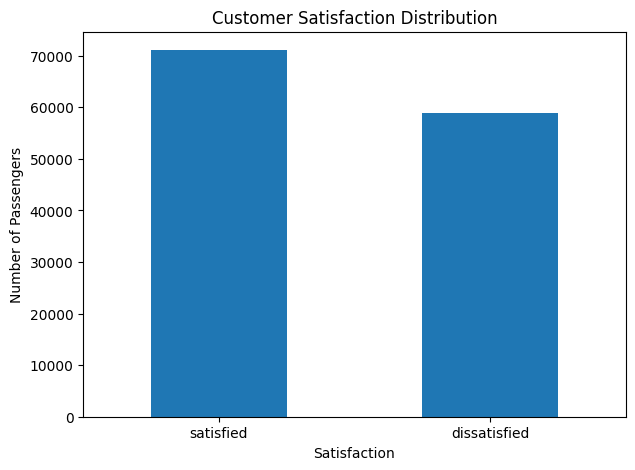

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

df["satisfaction"].value_counts().plot(kind="bar")

plt.title("Customer Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()

In [7]:
# Inspect records with missing arrival delay
missing_arrival = df[df["Arrival Delay in Minutes"].isna()]

print("Number of records with missing arrival delay:",
      len(missing_arrival))

display(missing_arrival.head(10))

Number of records with missing arrival delay: 393


,satisfaction,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
145,satisfied,Female,Loyal Customer,21,Personal Travel,Eco,4804,0,2,0,...,5,5,4,1,4,2,3,5,20,NaN
246,satisfied,Male,Loyal Customer,28,Personal Travel,Eco,1364,0,3,0,...,4,2,1,1,3,4,3,2,0,NaN
710,satisfied,Male,Loyal Customer,28,Personal Travel,Eco,1792,0,5,0,...,5,5,4,4,5,3,4,5,24,NaN
736,satisfied,Male,Loyal Customer,9,Personal Travel,Eco,1862,0,5,0,...,3,3,5,3,4,4,4,3,0,NaN
818,dissatisfied,Male,Loyal Customer,9,Personal Travel,Eco,1668,1,0,1,...,4,4,4,5,1,5,1,4,0,NaN
1162,dissatisfied,Male,Loyal Customer,23,Personal Travel,Eco,4650,1,1,1,...,2,2,1,3,4,4,4,2,0,NaN
1267,satisfied,Female,Loyal Customer,47,Personal Travel,Eco,846,0,5,0,...,2,3,3,0,3,5,3,5,0,NaN
1301,dissatisfied,Male,Loyal Customer,32,Personal Travel,Eco,1772,1,1,1,...,1,4,4,1,2,4,3,4,22,NaN
1910,dissatisfied,Male,Loyal Customer,47,Personal Travel,Eco,1396,1,2,1,...,4,4,1,1,4,4,4,4,17,NaN
2034,dissatisfied,Male,Loyal Customer,24,Personal Travel,Eco,4196,1,2,1,...,3,3,3,1,4,1,4,3,92,NaN


In [8]:
# Compare departure delay for missing arrival-delay records
print("Departure delay statistics for missing arrival-delay records:")
display(
    missing_arrival["Departure Delay in Minutes"].describe()
)

Departure delay statistics for missing arrival-delay records:


,Departure Delay in Minutes
count,393.000000
mean,37.885496
std,66.213936
min,0.000000
25%,0.000000
50%,8.000000
75%,48.000000
max,530.000000


In [9]:
# Compare satisfaction distribution
print("Satisfaction among records with missing arrival delay:")
display(
    missing_arrival["satisfaction"].value_counts(normalize=True).round(3)
)

Satisfaction among records with missing arrival delay:


,proportion
satisfaction,
satisfied,0.522
dissatisfied,0.478


In [10]:
print("Satisfaction among records with missing arrival delay:")

display(
    missing_arrival["satisfaction"]
    .value_counts()
)

print("\nPercentage:")

display(
    (missing_arrival["satisfaction"]
     .value_counts(normalize=True) * 100)
    .round(2)
)

Satisfaction among records with missing arrival delay:


,count
satisfaction,
satisfied,205
dissatisfied,188



Percentage:


,proportion
satisfaction,
satisfied,52.16
dissatisfied,47.84


In [11]:
rating_columns = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]

for col in rating_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Unique values:", sorted(df[col].unique()))


Seat comfort
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Departure/Arrival time convenient
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Food and drink
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Gate location
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Inflight wifi service
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Inflight entertainment
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Online support
Minimum: 0
Maximum: 5
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Ease of Online booking
Minimum: 0
Maximum: 5

In [12]:
# Check how frequently 0 appears in the service-rating columns

rating_cols = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]

zero_counts = (df[rating_cols] == 0).sum()

zero_percentages = ((df[rating_cols] == 0).mean() * 100).round(2)

zero_summary = pd.DataFrame({
    "Zero Count": zero_counts,
    "Zero Percentage": zero_percentages
})

display(zero_summary.sort_values("Zero Count", ascending=False))

,Zero Count,Zero Percentage
Departure/Arrival time convenient,6664,5.13
Food and drink,5945,4.58
Seat comfort,4797,3.69
Inflight entertainment,2978,2.29
Leg room service,444,0.34
Inflight wifi service,132,0.10
Ease of Online booking,18,0.01
Online boarding,14,0.01
Cleanliness,5,0.00
On-board service,5,0.00


In [13]:
# Compare satisfaction for passengers with and without zero ratings

for col in rating_cols:
    zero_satisfaction = pd.crosstab(
        df[col] == 0,
        df["satisfaction"],
        normalize="index"
    ) * 100

    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")

    display(zero_satisfaction.round(2))


Seat comfort


satisfaction,dissatisfied,satisfied
Seat comfort,,
False,47.00,53.00
True,0.21,99.79



Departure/Arrival time convenient


satisfaction,dissatisfied,satisfied
Departure/Arrival time convenient,,
False,45.24,54.76
True,45.81,54.19



Food and drink


...

satisfaction,dissatisfied,satisfied
Checkin service,,
False,45.27,54.73
True,100.00,0.00



Cleanliness


satisfaction,dissatisfied,satisfied
Cleanliness,,
False,45.27,54.73
True,100.00,0.00



Online boarding


satisfaction,dissatisfied,satisfied
Online boarding,,
False,45.26,54.74
True,100.00,0.00


In [14]:
# Investigate who has zero service ratings

zero_analysis_cols = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]

for col in zero_analysis_cols:
    zero_rows = df[df[col] == 0]

    print(f"\n{'='*70}")
    print(f"{col} = 0")
    print(f"Number of records: {len(zero_rows)}")
    print(f"{'='*70}")

    if len(zero_rows) > 0:
        print("\nClass:")
        display(zero_rows["Class"].value_counts(normalize=True).mul(100).round(2))

        print("\nType of Travel:")
        display(
            zero_rows["Type of Travel"]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )


Seat comfort = 0
Number of records: 4797

Class:


,proportion
Class,
Business,53.20
Eco,39.65
Eco Plus,7.15



Type of Travel:


,proportion
Type of Travel,
Business travel,64.85
Personal Travel,35.15



Departure/Arrival time convenient = 0
Number of records: 6664

Class:


...

,proportion
Type of Travel,
Business travel,100.0



Online boarding = 0
Number of records: 14

Class:


,proportion
Class,
Eco Plus,42.86
Eco,28.57
Business,28.57



Type of Travel:


,proportion
Type of Travel,
Business travel,100.0


Categorical EDA



In [15]:
# Satisfaction across important categorical variables

categorical_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for col in categorical_cols:
    print(f"\n{'='*60}")
    print(f"{col} vs Satisfaction")
    print(f"{'='*60}")

    result = pd.crosstab(
        df[col],
        df["satisfaction"],
        normalize="index"
    ) * 100

    display(result.round(2))


Gender vs Satisfaction


satisfaction,dissatisfied,satisfied
Gender,,
Female,34.86,65.14
Male,55.99,44.01



Customer Type vs Satisfaction


satisfaction,dissatisfied,satisfied
Customer Type,,
Loyal Customer,38.37,61.63
disloyal Customer,76.03,23.97



Type of Travel vs Satisfaction


satisfaction,dissatisfied,satisfied
Type of Travel,,
Business travel,41.63,58.37
Personal Travel,53.39,46.61



Class vs Satisfaction


satisfaction,dissatisfied,satisfied
Class,,
Business,29.06,70.94
Eco,60.60,39.40
Eco Plus,57.29,42.71


In [16]:
class_satisfaction = pd.crosstab(
    df["Class"],
    df["satisfaction"],
    normalize="index"
) * 100

class_satisfaction = class_satisfaction.reset_index()

class_satisfaction

satisfaction,Class,dissatisfied,satisfied
0,Business,29.062098,70.937902
1,Eco,60.601279,39.398721
2,Eco Plus,57.294655,42.705345


In [17]:
service_cols = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]

service_comparison = df.groupby("satisfaction")[service_cols].mean().T

service_comparison = service_comparison.rename(
    columns={
        "dissatisfied": "Dissatisfied Mean",
        "satisfied": "Satisfied Mean"
    }
)

service_comparison["Difference"] = (
    service_comparison["Satisfied Mean"]
    - service_comparison["Dissatisfied Mean"]
)

service_comparison = service_comparison.sort_values(
    "Difference",
    ascending=False
)

service_comparison.round(3)

satisfaction,Dissatisfied Mean,Satisfied Mean,Difference
Inflight entertainment,2.609,4.024,1.416
Ease of Online booking,2.852,3.985,1.132
Online support,2.959,3.983,1.024
On-board service,2.973,3.872,0.899
Online boarding,2.870,3.752,0.882
Leg room service,3.053,3.844,0.792
Seat comfort,2.467,3.146,0.678
Checkin service,2.972,3.646,0.674
Baggage handling,3.365,3.969,0.605
Inflight wifi service,2.920,3.521,0.602


---
## Service Rating & Churn Gap Analysis
Evaluating how individual in-flight and ground service ratings (0–5) influence overall passenger sentiment and churn risk.

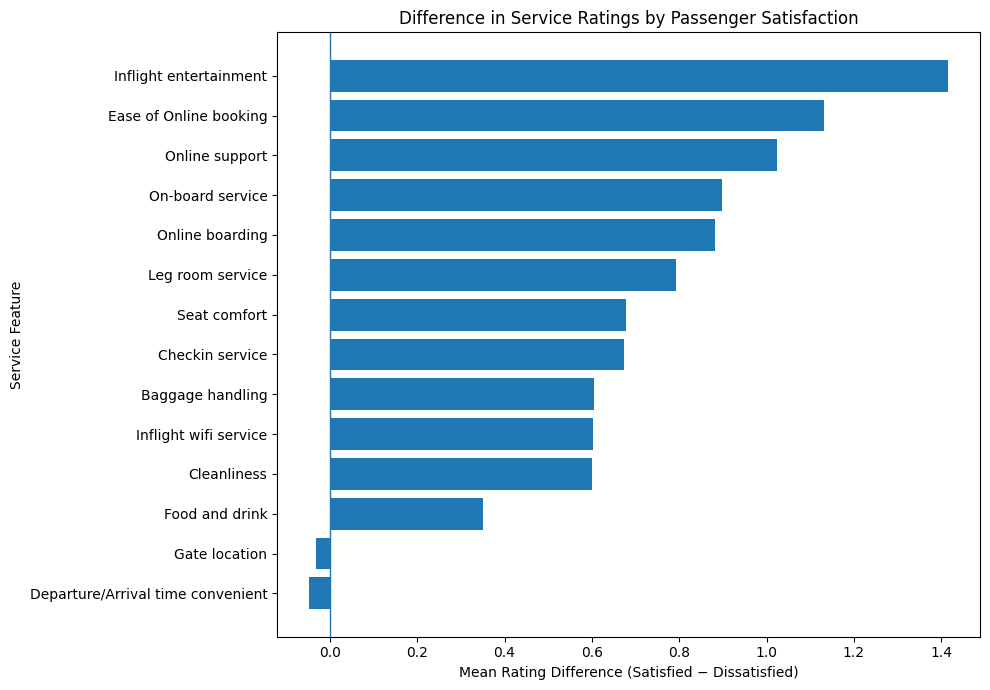

In [18]:
import matplotlib.pyplot as plt

plot_data = service_comparison.sort_values("Difference")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data.index,
    plot_data["Difference"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Mean Rating Difference (Satisfied − Dissatisfied)")
plt.ylabel("Service Feature")
plt.title("Difference in Service Ratings by Passenger Satisfaction")

plt.tight_layout()
plt.show()

> **Business Insight:**
> * **Inflight Entertainment ($\Delta = +1.41$)** and **Ease of Online Booking ($\Delta = +1.13$)** show the largest rating deltas between satisfied and dissatisfied passengers.
> * Cabin entertainment and digital touchpoints are the primary levers for customer retention.

In [19]:
delay_cols = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

delay_comparison = df.groupby("satisfaction")[delay_cols].agg(
    ["mean", "median", "std"]
)

delay_comparison.round(2)

Departure Delay in Minutes                \
                                   mean median    std   
satisfaction                                            
dissatisfied                      17.81    0.0  43.51   
satisfied                         12.15    0.0  32.68   

             Arrival Delay in Minutes                
                                 mean median    std  
satisfaction                                         
dissatisfied                    18.50    0.0  43.85  
satisfied                       12.27    0.0  33.10

In [20]:
delay_summary = df.groupby("satisfaction").agg(
    Departure_Delayed=(
        "Departure Delay in Minutes",
        lambda x: (x > 0).mean() * 100
    ),
    Arrival_Delayed=(
        "Arrival Delay in Minutes",
        lambda x: (x > 0).mean() * 100
    )
)

delay_summary.round(2)

,Departure_Delayed,Arrival_Delayed
satisfaction,,
dissatisfied,46.64,48.53
satisfied,40.94,39.67


In [21]:

# Compare age and flight distance by satisfaction

age_distance_summary = df.groupby("satisfaction").agg(
    Age_Mean=("Age", "mean"),
    Age_Median=("Age", "median"),
    Flight_Distance_Mean=("Flight Distance", "mean"),
    Flight_Distance_Median=("Flight Distance", "median")
)

age_distance_summary.round(2)


,Age_Mean,Age_Median,Flight_Distance_Mean,Flight_Distance_Median
satisfaction,,,,
dissatisfied,37.47,36.0,2025.71,1955.0
satisfied,41.05,42.0,1944.77,1886.0


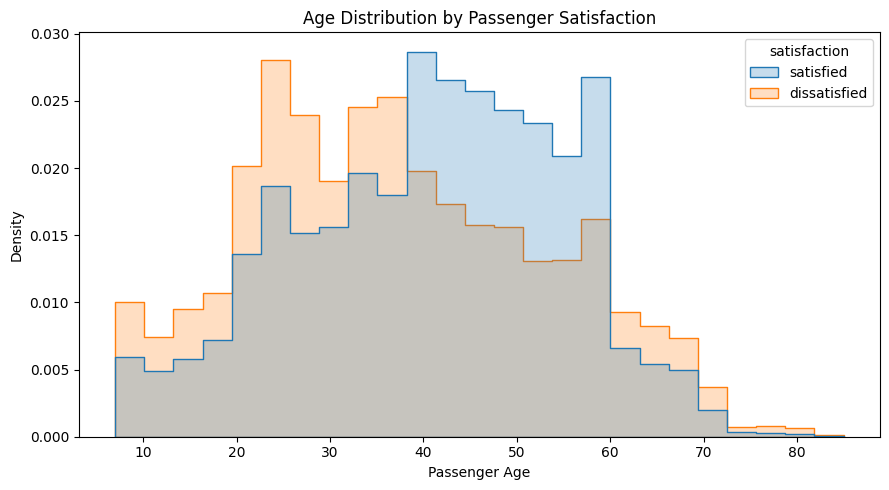

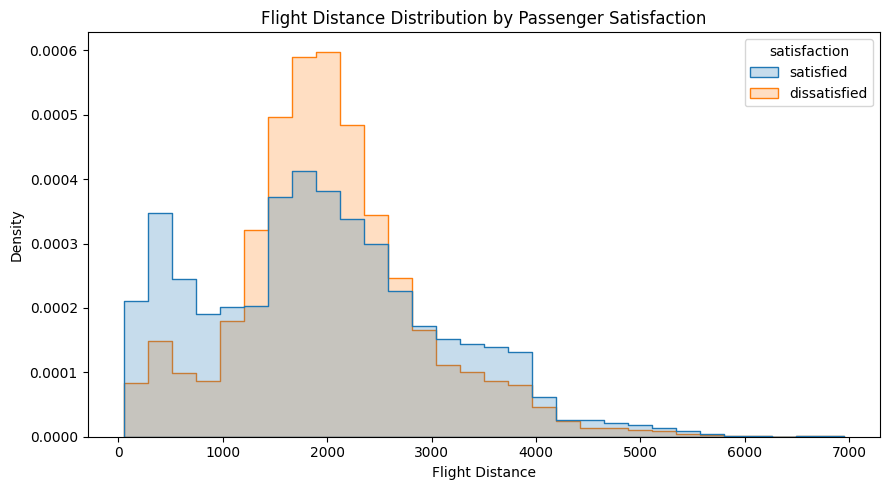

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

# Age distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="Age",
    hue="satisfaction",
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Age Distribution by Passenger Satisfaction")
plt.xlabel("Passenger Age")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# Flight distance distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="Flight Distance",
    hue="satisfaction",
    bins=30,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Flight Distance Distribution by Passenger Satisfaction")
plt.xlabel("Flight Distance")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [23]:

numeric_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

df[numeric_cols].describe().round(2)


,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.00,129880.00,129880.00,129487.00
mean,39.43,1981.41,14.71,15.09
std,15.12,1027.12,38.07,38.47
min,7.00,50.00,0.00,0.00
25%,27.00,1359.00,0.00,0.00
50%,40.00,1925.00,0.00,0.00
75%,51.00,2544.00,12.00,13.00
max,85.00,6951.00,1592.00,1584.00


In [24]:

numeric_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Potential_Outliers": outlier_count,
        "Outlier_Percentage": outlier_count / df[col].notna().sum() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary.round(2)


,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Potential_Outliers,Outlier_Percentage
0,Age,27.0,51.0,24.0,-9.0,87.0,0,0.00
1,Flight Distance,1359.0,2544.0,1185.0,-418.5,4321.5,2581,1.99
2,Departure Delay in Minutes,0.0,12.0,12.0,-18.0,30.0,18098,13.93
3,Arrival Delay in Minutes,0.0,13.0,13.0,-19.5,32.5,17492,13.51


---

##Numeric Feature Distributions
Analyzing the spread of passenger age, flight distances, and operational delays.


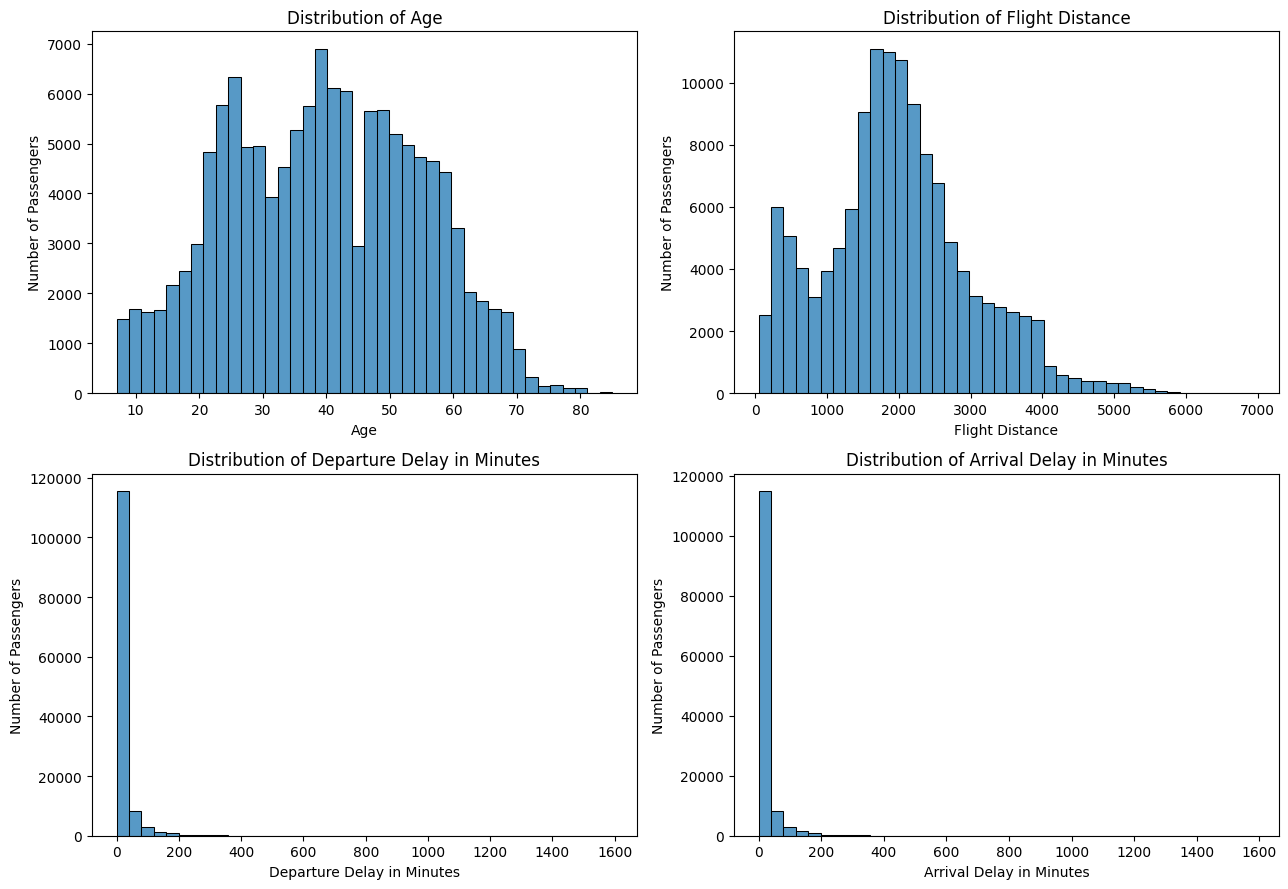

In [25]:

import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, bins=40, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Number of Passengers")

plt.tight_layout()
plt.show()


> **Key Observations:**
> * **Age:** Concentrated heavily between 25 and 60 years old, capturing working-age business travelers and vacationers.
> * **Flight Distance:** Right-skewed distribution centered primarily around medium-haul routes (1,500–2,000 miles).
> * **Delays:** Highly right-skewed with a massive spike at 0 minutes, indicating that scheduled on-time performance is standard.

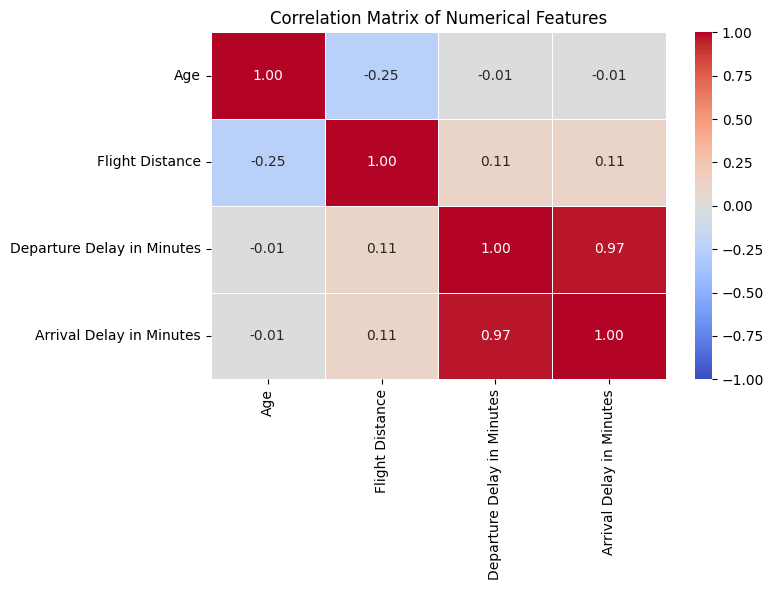

                             Age  Flight Distance  Departure Delay in Minutes  \
Age                         1.00            -0.25                       -0.01   
Flight Distance            -0.25             1.00                        0.11   
Departure Delay in Minutes -0.01             0.11                        1.00   
Arrival Delay in Minutes   -0.01             0.11                        0.97   

                            Arrival Delay in Minutes  
Age                                            -0.01  
Flight Distance                                 0.11  
Departure Delay in Minutes                      0.97  
Arrival Delay in Minutes                        1.00  


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns for correlation
numerical_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

# Calculate correlation matrix
corr_matrix = df[numerical_cols].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

print(corr_matrix.round(2))

In [27]:
import scipy.stats as stats
import numpy as np

def cramers_v(contingency_table):
    """Calculates Cramér's V statistic for categorical-categorical association."""
    chi2 = stats.chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Test categorical significance against 'satisfaction'
cat_cols = ["Gender", "Customer Type", "Type of Travel", "Class"]

for col in cat_cols:
    contingency = pd.crosstab(df[col], df["satisfaction"])
    chi2, p, dof, _ = stats.chi2_contingency(contingency)
    c_v = cramers_v(contingency)

    print(f"Feature: {col}")
    print(f"  Chi-Square Statistic: {chi2:.2f}")
    print(f"  p-value: {p:.4e}")
    print(f"  Cramér's V: {c_v:.3f}\n")

Feature: Gender
  Chi-Square Statistic: 5849.48
  p-value: 0.0000e+00
  Cramér's V: 0.212

Feature: Customer Type
  Chi-Square Statistic: 11117.54
  p-value: 0.0000e+00
  Cramér's V: 0.293

Feature: Type of Travel
  Chi-Square Statistic: 1549.40
  p-value: 0.0000e+00
  Cramér's V: 0.109

Feature: Class
  Chi-Square Statistic: 12671.68
  p-value: 0.0000e+00
  Cramér's V: 0.312



---
##Machine Learning Modeling & Evaluation
Training classification models (Logistic Regression, Gradient Boosting, and Random Forest) using rigorous splitting protocols to eliminate data leakage.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Fill missing arrival delays with the median value
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Arrival Delay in Minutes"].median())

# 2. Separate features (X) and target (y)
X = df.drop(columns=["satisfaction"])
y = df["satisfaction"]

# 3. Convert text categories into numerical columns (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (103904, 23)
Testing set shape: (25976, 23)


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Train the model on the training data
rf_model.fit(X_train, y_train)

# 3. Predict on the test data
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate performance
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9590006159531875

Classification Report:
               precision    recall  f1-score   support

dissatisfied       0.95      0.96      0.96     11759
   satisfied       0.97      0.96      0.96     14217

    accuracy                           0.96     25976
   macro avg       0.96      0.96      0.96     25976
weighted avg       0.96      0.96      0.96     25976



In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Create a pipeline with a standard scaler and logistic regression
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# 2. Train the model
log_reg.fit(X_train, y_train)

# 3. Predict and evaluate
y_pred_lr = log_reg.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.8368878965198645

Classification Report:
               precision    recall  f1-score   support

dissatisfied       0.82      0.82      0.82     11759
   satisfied       0.85      0.85      0.85     14217

    accuracy                           0.84     25976
   macro avg       0.84      0.84      0.84     25976
weighted avg       0.84      0.84      0.84     25976



In [31]:
from sklearn.ensemble import GradientBoostingClassifier

# 1. Initialize the Gradient Boosting model
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)

# 2. Train the model
gb_model.fit(X_train, y_train)

# 3. Predict and evaluate
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.9267400677548506

Classification Report:
               precision    recall  f1-score   support

dissatisfied       0.92      0.92      0.92     11759
   satisfied       0.93      0.93      0.93     14217

    accuracy                           0.93     25976
   macro avg       0.93      0.93      0.93     25976
weighted avg       0.93      0.93      0.93     25976



--- Logistic Regression ---
ROC-AUC Score: 0.9100
Confusion Matrix:
 [[ 9641  2118]
 [ 2119 12098]]


--- Gradient Boosting ---
ROC-AUC Score: 0.9823
Confusion Matrix:
 [[10806   953]
 [  950 13267]]


--- Random Forest ---
ROC-AUC Score: 0.9931
Confusion Matrix:
 [[11326   433]
 [  632 13585]]




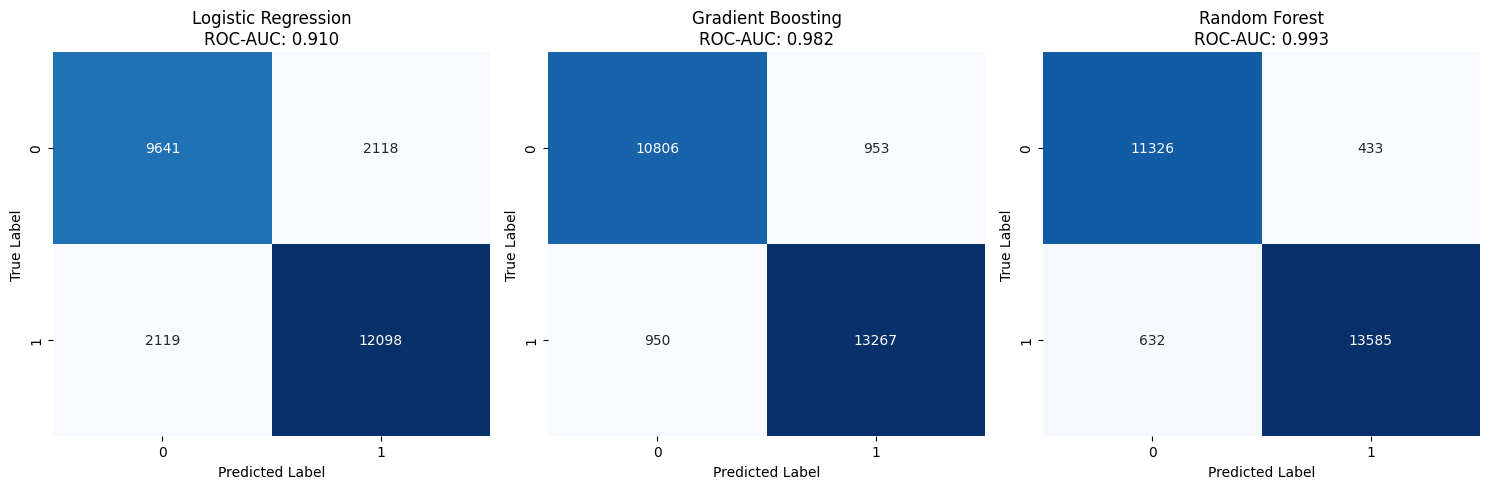

In [32]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": log_reg,
    "Gradient Boosting": gb_model,
    "Random Forest": rf_model
}

plt.figure(figsize=(15, 5))

for i, (name, model) in enumerate(models.items(), 1):
    # Predict probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)

    # Predict classes for Confusion Matrix
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    print(f"--- {name} ---")
    print(f"ROC-AUC Score: {auc:.4f}")
    print("Confusion Matrix:\n", cm)
    print("\n")

    # Plot Confusion Matrix subplot
    plt.subplot(1, 3, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"{name}\nROC-AUC: {auc:.3f}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

plt.tight_layout()
plt.show()

Top 15 Most Important Features:


,Feature,Importance
7,Inflight entertainment,0.188666
2,Seat comfort,0.137961
9,Ease of Online booking,0.081200
8,Online support,0.058933
19,Customer Type_disloyal Customer,0.046947
10,On-board service,0.043626
4,Food and drink,0.038641
11,Leg room service,0.038500
1,Flight Distance,0.035263
20,Type of Travel_Personal Travel,0.033660


/tmp/ipykernel_1900/1856847984.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


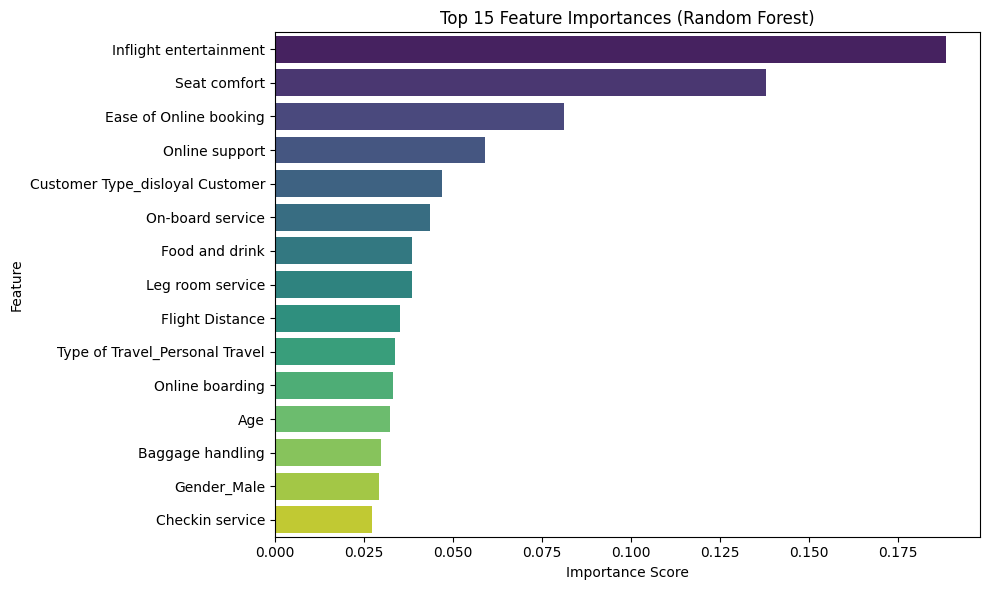

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# 2. Create a DataFrame for easy viewing and sorting
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# 3. Display top 15 most important features
print("Top 15 Most Important Features:")
display(feature_importance_df.head(15))

# 4. Plot top 15 feature importances
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature",
    palette="viridis"
)
plt.title("Top 15 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

--- Top 10 Logistic Regression Coefficients (Linear Drivers) ---


,Feature,Coefficient
7,Inflight entertainment,0.929499
19,Customer Type_disloyal Customer,-0.758750
18,Gender_Male,-0.483542
2,Seat comfort,0.399867
10,On-board service,0.383496
13,Checkin service,0.368365
21,Class_Eco,-0.364637
20,Type of Travel_Personal Travel,-0.353807
4,Food and drink,-0.313267
9,Ease of Online booking,0.295804



--- Top 10 Permutation Importances (Random Forest) ---


,Feature,Importance_Mean,Importance_Std
2,Seat comfort,0.127433,0.001265
19,Customer Type_disloyal Customer,0.067709,0.000648
7,Inflight entertainment,0.043787,0.001197
18,Gender_Male,0.039975,0.000831
20,Type of Travel_Personal Travel,0.032553,0.000406
13,Checkin service,0.027094,0.000628
12,Baggage handling,0.022698,0.000721
8,Online support,0.021220,0.000605
14,Cleanliness,0.018617,0.000768
15,Online boarding,0.017716,0.000600


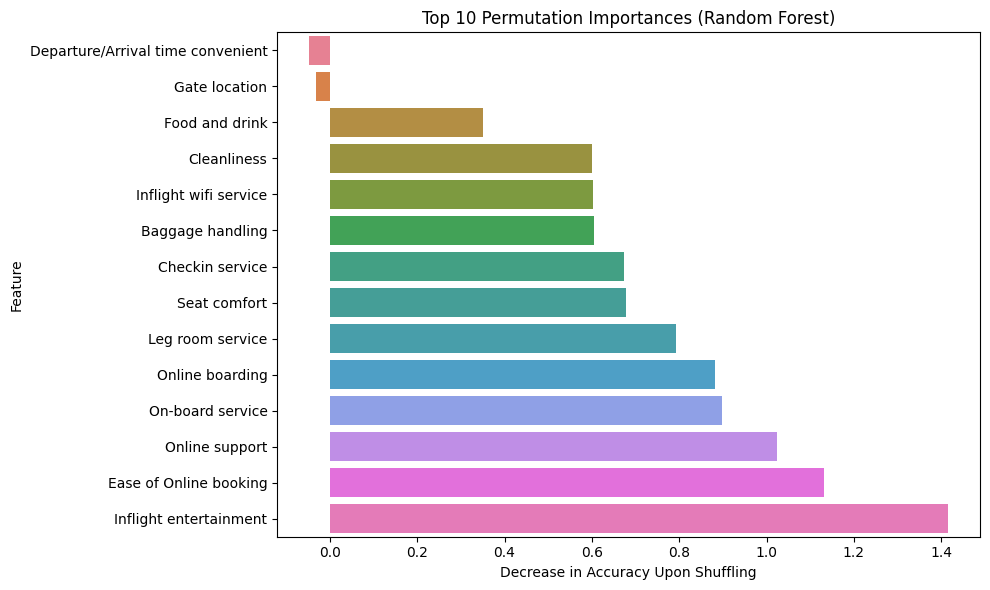

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# 1. Logistic Regression Coefficients (Linear Direction & Weight)
feature_names = X_encoded.columns
lr_model = log_reg.named_steps['logisticregression']

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.coef_[0]
}).sort_values(by="Coefficient", key=abs, ascending=False)

print("--- Top 10 Logistic Regression Coefficients (Linear Drivers) ---")
display(coef_df.head(10))

# 2. Permutation Importance for Random Forest (Model-Agnostic Feature Reliance)
perm_result = permutation_importance(
    rf_model, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values(by="Importance_Mean", ascending=False)

print("\n--- Top 10 Permutation Importances (Random Forest) ---")
display(perm_df.head(10))

# Plot Permutation Importances
plt.figure(figsize=(10, 6))
sns.barplot(
    x=plot_data["Difference"],
    y=plot_data.index,
    hue=plot_data.index,
    legend=False
)
plt.title("Top 10 Permutation Importances (Random Forest)")
plt.xlabel("Decrease in Accuracy Upon Shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Model Performance Summary
| Model | Accuracy | ROC-AUC |
| :--- | :---: | :---: |
| Logistic Regression | 83.7% | 0.910 |
| Gradient Boosting | 92.7% | 0.982 |
| **Random Forest (Champion)** | **95.9%** | **0.993** |

> **Conclusion:** The **Random Forest Classifier** is selected as the champion model because it effectively captures non-linear interactions across service rating features.